# Snapget — chuẩn bị tập ảnh Việt Nam cho lần train 9 lớp

Lần train mới chỉ giữ 9 lớp của 6 quest: cup, bottle, book, chair, laptop, keyboard, umbrella, bicycle, motorcycle. Bỏ potted plant, backpack, clock.

| Nhiệm vụ | Đầu vào (Drive `snapget-ml/data/`) | Kết quả |
|---|---|---|
| 1 | `snapget_vn_supplement.zip` | Lọc còn 9 lớp, **ghi đè** `snapget_vn_supplement.zip` |
| 2 | `vn.zip` | Lọc còn 9 lớp (giữ trên Colab, gộp ở nhiệm vụ 4) |
| 3 | `bosung.zip` | Tự vẽ box, gán nhãn, chia vào phần train/test còn thiếu |
| 4 | kết quả 2 + 3 | `vnreal.zip` **ghi đè** `vn.zip` |

- File cũ được sao lưu vào `snapget-ml/data/backup/` trước khi ghi đè.
- Nhiệm vụ 3 cần GPU (Runtime → Change runtime type → T4); các nhiệm vụ còn lại chạy được trên CPU.

In [10]:
# 0a. Drive
from google.colab import drive
drive.mount('/content/drive')
import os, shutil, time
WORK = '/content/drive/MyDrive/snapget-ml'
DATA = f'{WORK}/data'
PREP = '/content/vnprep'        # thư mục làm việc trên đĩa Colab
BACKUP = True                   # sao lưu file cũ trước khi ghi đè
os.makedirs(PREP, exist_ok=True)

def put_on_drive(local, name):
    dst = f'{DATA}/{name}'
    if BACKUP and os.path.exists(dst):
        bak = f'{DATA}/backup/{name[:-4]}_{time.strftime("%Y%m%d-%H%M")}.zip'
        os.makedirs(os.path.dirname(bak), exist_ok=True)
        shutil.copy2(dst, bak)
        print('sao lưu:', bak)
    shutil.copy2(local, dst)
    print('->', dst, f'({os.path.getsize(dst) / 1e6:.0f} MB)')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
# 0b. Code + thư viện
%cd /content
!rm -rf datn && git clone --depth 1 https://github.com/HuyenVt001/datn.git datn
%cd /content/datn/ml
!pip install -q "ultralytics>=8.3,<9" pyyaml pillow-heif

/content
Cloning into 'datn'...
remote: Enumerating objects: 822, done.
remote: Counting objects: 100% (822/822), done.
remote: Compressing objects: 100% (732/732), done.
remote: Total 822 (delta 64), reused 449 (delta 27), pack-reused 0 (from 0)
Receiving objects: 100% (822/822), 55.06 MiB | 20.05 MiB/s, done.
Resolving deltas: 100% (64/64), done.
/content/datn/ml


## 1. Lọc `snapget_vn_supplement` còn 9 lớp
- Box của lớp bị bỏ được xoá khỏi file nhãn; chỉ số lớp đánh lại theo `data.yaml` 9 lớp.
- Ảnh mang tên lớp bị bỏ (vd `gg_clock_0012`): nếu còn box lớp khác (vd có ghế) thì giữ và đổi tên theo lớp đó, không thì xoá.
- `metadata.csv` và `README.md` được cập nhật theo.

In [ ]:
!rm -rf {PREP}/raw/sup {PREP}/sup9 && mkdir -p {PREP}/raw/sup
!unzip -q -o "{DATA}/snapget_vn_supplement.zip" -d {PREP}/raw/sup
!python scripts/18_prepare_vn_data.py filter --src {PREP}/raw/sup --out {PREP}/sup9/snapget_vn_supplement
if os.path.exists(f'{PREP}/sup9/snapget_vn_supplement/data.yaml'):
    !cd {PREP}/sup9 && rm -f ../snapget_vn_supplement.zip && zip -q -r ../snapget_vn_supplement.zip snapget_vn_supplement
    put_on_drive(f'{PREP}/snapget_vn_supplement.zip', 'snapget_vn_supplement.zip')

## 2. Lọc `vn.zip` còn 9 lớp
- Train: giống nhiệm vụ 1.
- Test: ảnh mang tên lớp bị bỏ mà không còn box lớp nào khác được giữ làm **ảnh âm** (`self_neg_xxxx`), vì đây vẫn là ảnh thật tốt để kiểm tra nhận nhầm.
- Cuối ô in số ảnh test của từng nhóm quest và phần còn thiếu so với mục tiêu 85 ảnh/nhóm (khoảng 50 ảnh vào real_test). Đây là số ảnh nên chụp thêm cho `bosung.zip`.

In [12]:
!rm -rf {PREP}/raw/vn {PREP}/vn9 && mkdir -p {PREP}/raw/vn
!unzip -q -o "{DATA}/vn.zip" -d {PREP}/raw/vn
!python scripts/18_prepare_vn_data.py filter --src {PREP}/raw/vn --out {PREP}/vn9

Giu 9 lop: ['cup', 'bottle', 'book', 'chair', 'laptop', 'keyboard', 'umbrella', 'bicycle', 'motorcycle'] | bo: ['potted plant', 'backpack', 'clock']
{"images": {"train": 1840, "test": 718}, "deleted": {"train": 293}, "renamed": {"train": 138, "test": 50}, "toNegative": {"test": 91}, "droppedBoxes": {"potted plant": 1219, "backpack": 359, "clock": 454}}
  [train] 1840 anh | bicycle 368 | laptop 327 | umbrella 172 | chair 225 | cup 537 | book 225 | hardneg 160 | neg 160
  [test] 718 anh | bicycle 120 | laptop 111 | umbrella 45 | chair 66 | cup 174 | book 78 | hardneg 55 | neg 143
  [test] con thieu so voi muc tieu: umbrella 40, chair 19, book 7
OK


## 3. Gán nhãn tự động `bosung.zip`
Ảnh tự chụp xếp theo thư mục, **tên thư mục = lớp chính** (tên tiếng Anh như trên):
```
bosung.zip
└─ bosung/
   ├─ umbrella/   *.jpg
   ├─ chair/      *.jpg
   ├─ book/ ...
   ├─ hardneg/    ảnh âm khó: nón lá, áo mưa, tablet, menu quán, ảnh vật trên màn hình...
   ├─ neg/        ảnh không có vật nào
   └─ test/umbrella/ ...   (tuỳ chọn: ép vào test; tương tự train/)
```
- Hai detector cùng chạy: y1-s (đã học ảnh Việt Nam) và YOLO11x COCO. Box cùng lớp được gộp. Lớp chính lấy ngưỡng thấp hơn để ít bỏ sót.
- Box được vẽ cho **mọi** lớp trong 9 lớp xuất hiện trong ảnh, không chỉ lớp chính.
- Chia tập: lấp phần test còn thiếu của từng nhóm trước, còn lại vào train. Ảnh chụp liền nhau được giữ chung một tập để hạn chế rò rỉ train ↔ test.
- Ảnh được đổi tên tiếp số thứ tự của `vn.zip` (vd `self_umbrella_0046.jpg`), xoay đúng chiều theo EXIF; ảnh `.heic` được chuyển sang `.jpg`.
- Ảnh nhãn chưa chắc chắn (không thấy lớp chính, box nghi vấn, ảnh âm có vật thể) được đánh dấu trong `bosung_log.csv` và hiện ở cuối ô.

In [13]:
BOSUNG = f'{DATA}/bosung'      # ảnh bổ sung đã giải nén trên Drive
assert os.path.isdir(BOSUNG), f'Không thấy thư mục {BOSUNG}'
!rm -rf {PREP}/bosung_auto
Y1 = f'{WORK}/artifacts/y1-s/best.pt'
!python scripts/18_prepare_vn_data.py autolabel --src "{BOSUNG}" --vn {PREP}/vn9 \
    --out {PREP}/bosung_auto/bosung --y1 {Y1} --coco yolo11x.pt --test-target 85
if os.path.exists(f'{PREP}/bosung_auto/bosung/data.yaml'):
    !cd {PREP}/bosung_auto && rm -f bosung_review.zip && zip -q -r bosung_review.zip bosung
    shutil.copy2(f'{PREP}/bosung_auto/bosung_review.zip', f'{DATA}/bosung_review.zip')
    shutil.copy2(f'{PREP}/bosung_auto/bosung_log.csv', f'{DATA}/bosung_log.csv')
    print('-> Drive: bosung_review.zip, bosung_log.csv')

Giu 9 lop: ['cup', 'bottle', 'book', 'chair', 'laptop', 'keyboard', 'umbrella', 'bicycle', 'motorcycle'] | bo: ['potted plant', 'backpack', 'clock']
  224 anh: book 72, chair 32, cup 28, hardneg 29, umbrella 63
  detector y1: /content/drive/MyDrive/snapget-ml/artifacts/y1-s/best.pt
  detector coco: yolo11x.pt
{
 "images": 224,
 "skipped": 0,
 "flagged": 67,
 "split": {
  "train": 153,
  "test": 71
 },
 "testAdded": {
  "book": 7,
  "chair": 19,
  "hardneg": 5,
  "umbrella": 40
 },
 "testStillShort": {},
 "detectors": [
  "y1",
  "coco"
 ]
}
OK
-> Drive: bosung_review.zip, bosung_log.csv


67 ảnh cần soát


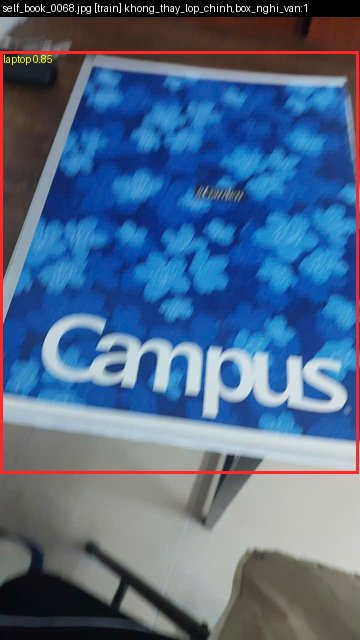

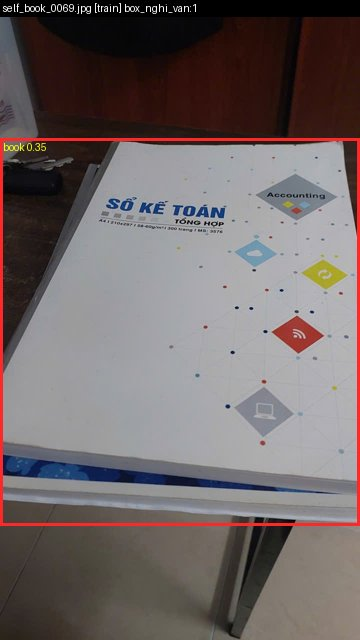

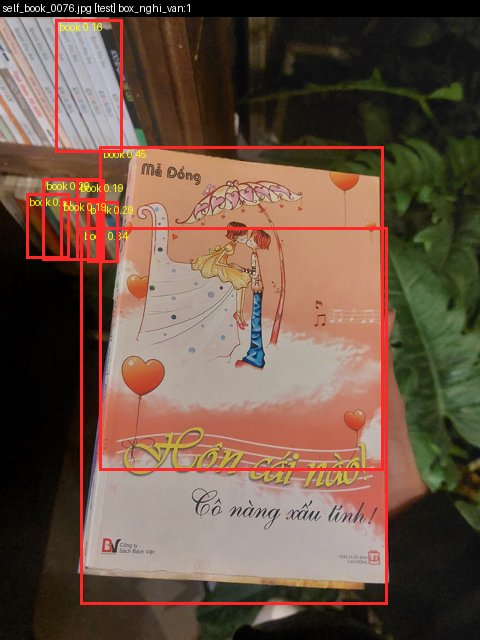

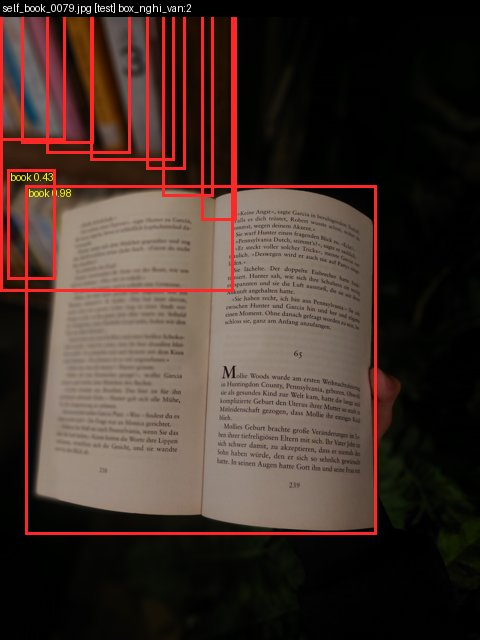

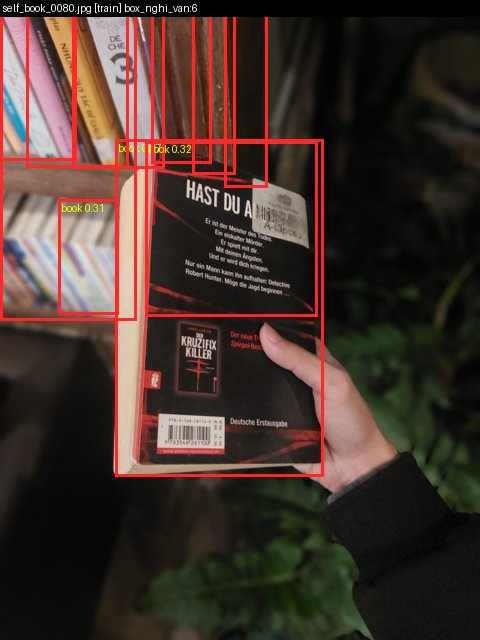

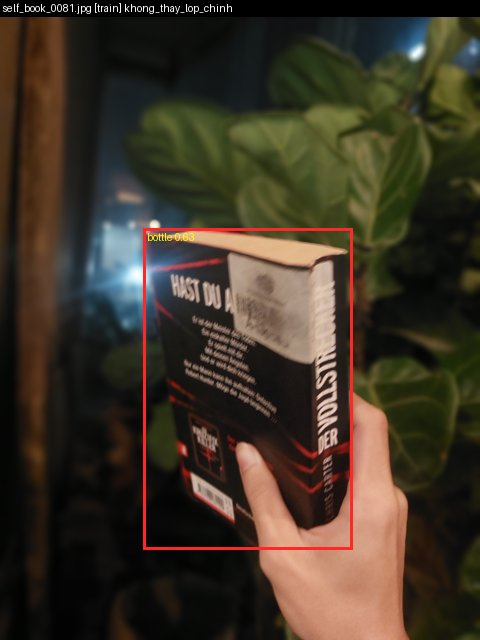

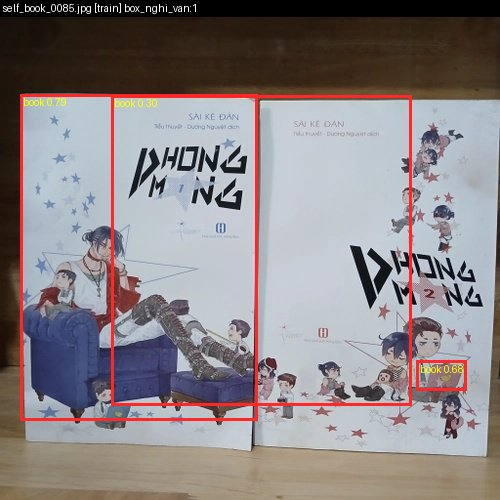

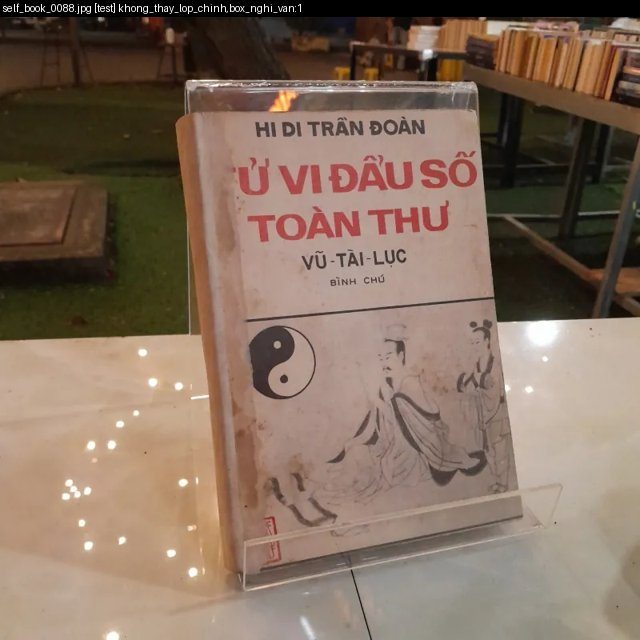

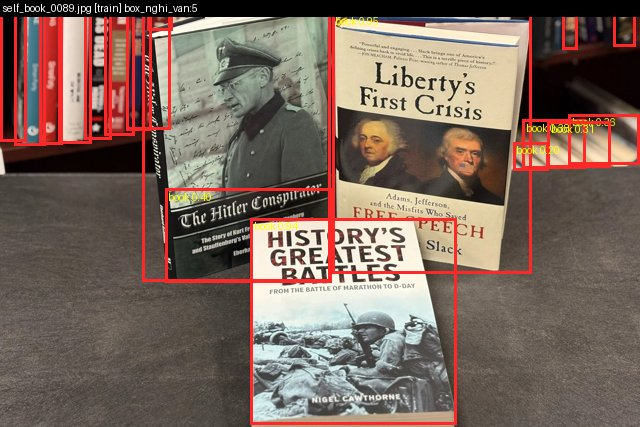

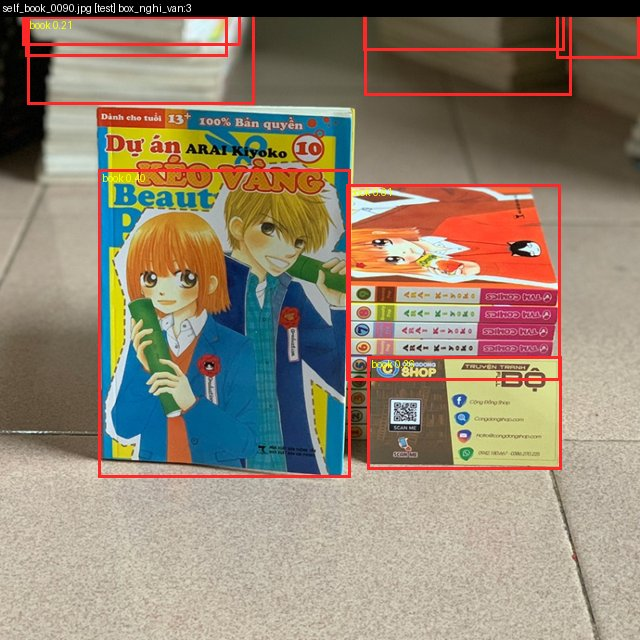

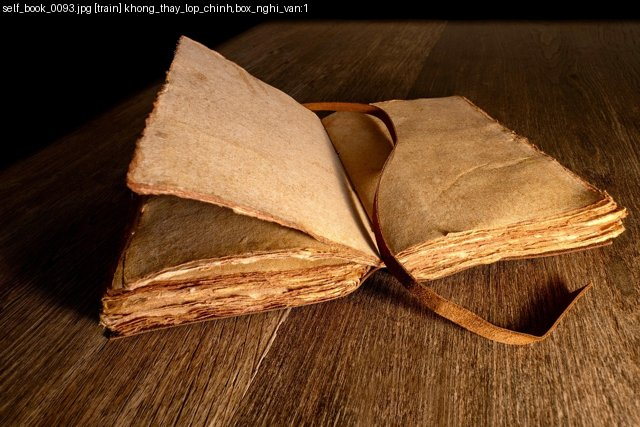

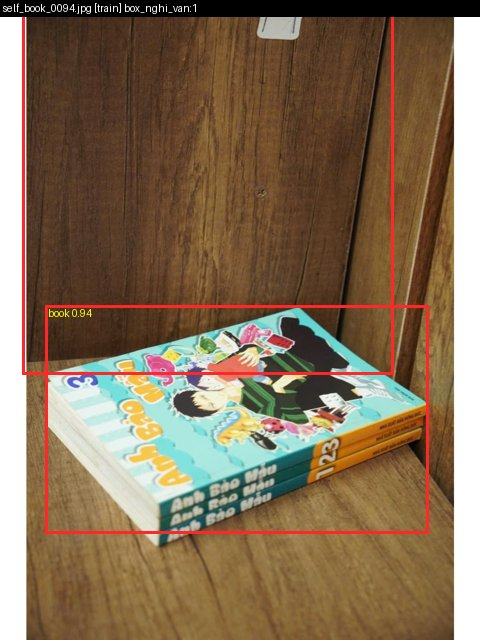

In [14]:
# Ảnh cần soát (tối đa 12): khung đỏ = box tự động
import glob
from IPython.display import Image, display
prev = sorted(glob.glob(f'{PREP}/bosung_auto/bosung_preview/*.jpg'))
print(f'{len(prev)} ảnh cần soát')
for p in prev[:12]:
    display(Image(p, width=320))

### Soát nhãn (bắt buộc với ảnh vào test)
Nhãn tự động có thể sót hoặc sai box. Nếu đưa thẳng vào test, số liệu đánh giá sẽ sai lệch, nên nhiệm vụ 4 **không nhận ảnh test chưa soát**.
1. Tải `bosung_review.zip` từ Drive về, giải nén. Roboflow → *Create Project* (Object Detection) → *Upload* cả thư mục `bosung` (Roboflow tự đọc nhãn YOLO và `data.yaml`).
2. Soát từng ảnh, ưu tiên các ảnh có cột `flags` trong `bosung_log.csv`: vẽ box còn sót, xoá box sai, xoá ảnh hỏng.
3. *Generate version*: bỏ hết Preprocessing và Augmentation → *Export* định dạng YOLOv8 → đổi tên file thành `bosung_reviewed.zip` → đặt vào `snapget-ml/data/`.

Tên file có thêm đuôi `_jpg.rf.xxx` của Roboflow không sao, script tự nhận lại.

## 4. Gộp thành `vnreal.zip` và ghi đè `vn.zip`
- Gộp `vn` đã lọc (nhiệm vụ 2) với ảnh bổ sung (nhiệm vụ 3). Có `bosung_reviewed.zip` thì dùng nhãn đã soát; ảnh bị xoá khi soát sẽ bị bỏ.
- Chưa soát: ảnh nhãn không chắc chắn bị bỏ; ảnh test chỉ được nhận khi đặt `ALLOW_UNREVIEWED_TEST = True`.
- In số ảnh cuối cùng từng nhóm và phần test còn thiếu.

In [15]:
ALLOW_UNREVIEWED_TEST = False
REV = f'{DATA}/bosung_reviewed.zip'
rev = ''
if os.path.exists(REV):
    !rm -rf {PREP}/raw/reviewed && mkdir -p {PREP}/raw/reviewed && unzip -q -o "{REV}" -d {PREP}/raw/reviewed
    rev = f'--reviewed {PREP}/raw/reviewed'
else:
    print('Chưa có bosung_reviewed.zip -> dùng nhãn tự động')
flag = '--allow-unreviewed-test' if ALLOW_UNREVIEWED_TEST else ''
!rm -rf {PREP}/vnreal {PREP}/vnreal.zip
!python scripts/18_prepare_vn_data.py merge --vn {PREP}/vn9 --bosung {PREP}/bosung_auto/bosung {rev} {flag} \
    --out {PREP}/vnreal/vn
if os.path.exists(f'{PREP}/vnreal/vn/data.yaml'):
    !cd {PREP}/vnreal && zip -q -r ../vnreal.zip vn
    put_on_drive(f'{PREP}/vnreal.zip', 'vn.zip')

Chưa có bosung_reviewed.zip -> dùng nhãn tự động
Giu 9 lop: ['cup', 'bottle', 'book', 'chair', 'laptop', 'keyboard', 'umbrella', 'bicycle', 'motorcycle'] | bo: ['potted plant', 'backpack', 'clock']
  bo 21 anh chua soat ma nhan tu dong khong chac (khong thay lop chinh / anh am co vat the)
!! 67 anh bo sung vao TEST chua duoc soat nhan. Nhan tu dong co the sot/sai box, dua vao test se lam so lieu danh gia sai lech (DATASET_SPEC muc D.6). Soat tren Roboflow roi dat bosung_reviewed.zip, hoac chay lai voi --allow-unreviewed-test neu chap nhan.


Notebook train đọc `vn.zip` và `snapget_vn_supplement.zip` mới. Hai file giờ chỉ còn 9 lớp, nên pipeline train cũng phải chuyển sang 9 lớp trước khi train lại.